<a href="https://colab.research.google.com/github/clem-ea/GSLC_DeepLearning/blob/main/GSLC_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import random
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split

# Menjaga reproduksibilitas
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan device: {device}")

Menggunakan device: cuda


In [ ]:
weights = models.ResNet18_Weights.IMAGENET1K_V1

# Transformasi Data Latih (Dengan Augmentasi untuk B4)
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])

# Transformasi Evaluasi (Tanpa Augmentasi / Deterministik)
eval_transforms = weights.transforms()

# Transformasi Dasar tanpa Augmentasi (Khusus Skenario Tanpa Augmentasi B4)
baseline_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])

In [ ]:
# 1. Unduh dataset penuh
full_dataset = datasets.OxfordIIITPet(root='./data', split='trainval', download=True)

# 2. Pilih 10 kelas (5 kucing, 5 anjing)
# Indeks kelas di Oxford-IIIT Pet:
# Kucing: Abyssinian(0), Bengal(1), Birman(2), Bombay(3), British_Shorthair(4)
# Anjing: beagle(12), boxer(13), chihuahua(14), pug(28), saint_bernard(29)
target_classes = [0, 1, 2, 3, 4, 12, 13, 14, 28, 29]
class_mapping = {old_label: new_label for new_label, old_label in enumerate(target_classes)}

# Filter indeks sampel yang termasuk dalam 10 kelas sasaran
filtered_indices = []
filtered_labels = []

for idx, (_, label) in enumerate(full_dataset):
    if label in target_classes:
        filtered_indices.append(idx)
        filtered_labels.append(class_mapping[label])

print(f"Total sampel terpilih (10 kelas): {len(filtered_indices)}")

# 3. Stratified Split: 70% Train, 15% Val, 15% Test
train_indices, temp_indices, train_labels, temp_labels = train_test_split(
    filtered_indices,
    filtered_labels,
    test_size=0.30,
    stratify=filtered_labels,
    random_state=42
)

val_indices, test_indices, _, _ = train_test_split(
    temp_indices,
    temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=42
)

print(f"Jumlah Train: {len(train_indices)} | Val: {len(val_indices)} | Test: {len(test_indices)}")

Total sampel terpilih (10 kelas): 996
Jumlah Train: 697 | Val: 149 | Test: 150


In [ ]:
class MappedSubset(torch.utils.data.Dataset):
    """Wrapper untuk menerapkan transformasi dan pemetaan ulang label kelas (0-9)"""
    def __init__(self, dataset, indices, class_mapping, transform=None):
        self.dataset = dataset
        self.indices = indices
        self.class_mapping = class_mapping
        self.transform = transform

    def __getitem__(self, idx):
        original_idx = self.indices[idx]
        image, label = self.dataset[original_idx]

        if self.transform:
            image = self.transform(image)

        new_label = self.class_mapping[label]
        return image, new_label

    def __len__(self):
        return len(self.indices)

# Buat instansiasi dataset
train_dataset = MappedSubset(full_dataset, train_indices, class_mapping, transform=train_transforms)
val_dataset = MappedSubset(full_dataset, val_indices, class_mapping, transform=eval_transforms)
test_dataset = MappedSubset(full_dataset, test_indices, class_mapping, transform=eval_transforms)

# Buat DataLoader
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

In [ ]:
import time
import csv
import pandas as pd
from sklearn.metrics import f1_score

class EarlyStopping:
    """Menghentikan pelatihan jika validation loss tidak membaik setelah beberapa epoch"""
    def __init__(self, patience=4, delta=1e-4):
        self.patience = patience
        self.delta = delta
        self.counter = 0
        self.best_loss = float('inf')
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.delta:
            self.best_loss = val_loss
            self.counter = 0
            self.best_model_state = model.state_dict().copy()
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data)
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct.double() / total
    return epoch_loss, epoch_acc.item()

def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    total = len(all_labels)
    epoch_loss = running_loss / total
    epoch_acc = np.sum(np.array(all_preds) == np.array(all_labels)) / total
    macro_f1 = f1_score(all_labels, all_preds, average='macro')

    return epoch_loss, epoch_acc, macro_f1, all_preds, all_labels

def run_experiment(exp_code, model, train_loader, val_loader, test_loader,
                   criterion, optimizer, device, max_epochs=20, patience=4):

    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())

    print(f"\n==========================================")
    print(f"Menjalankan Eksperimen: {exp_code}")
    print(f"Trainable Params: {trainable_params:,} / {total_params:,}")
    print(f"==========================================")

    early_stopping = EarlyStopping(patience=patience)
    history = []
    start_time = time.time()

    for epoch in range(1, max_epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc, val_f1, _, _ = evaluate(model, val_loader, criterion, device)

        print(f"Epoch [{epoch:02d}/{max_epochs:02d}] - "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

        history.append({
            'experiment': exp_code,
            'epoch': epoch,
            'train_loss': train_loss,
            'train_acc': train_acc,
            'val_loss': val_loss,
            'val_acc': val_acc,
            'val_f1': val_f1
        })

        early_stopping(val_loss, model)
        if early_stopping.early_stop:
            print(f"Early stopping dipicu pada epoch {epoch}.")
            break

    total_duration = time.time() - start_time

    # Muat bobot terbaik untuk evaluasi akhir pada test set
    model.load_state_dict(early_stopping.best_model_state)
    test_loss, test_acc, test_macro_f1, test_preds, test_labels = evaluate(model, test_loader, criterion, device)

    print(f"\n--- Hasil Uji Akhir ({exp_code}) ---")
    print(f"Konvergen pada Epoch : {len(history)}")
    print(f"Durasi Pelatihan     : {total_duration:.2f} detik")
    print(f"Akurasi Validasi     : {history[-1]['val_acc']:.4f}")
    print(f"Macro F1 (Test Set)  : {test_macro_f1:.4f}")

    summary = {
        'exp_code': exp_code,
        'trainable_params': trainable_params,
        'total_epochs': len(history),
        'duration_seconds': round(total_duration, 2),
        'val_acc': round(history[-1]['val_acc'], 4),
        'test_macro_f1': round(test_macro_f1, 4)
    }

    return summary, pd.DataFrame(history), (test_preds, test_labels)

In [ ]:
# Wadah penyimpan seluruh log eksperimen
all_summaries = []
all_epoch_logs = []

def save_logs_to_csv():
    # Simpan ringkasan konsolidasi (untuk Tabel C1)
    df_summary = pd.DataFrame(all_summaries)
    df_summary.to_csv("experiment_summary.csv", index=False)

    # Simpan log detail per epoch
    df_epochs = pd.concat(all_epoch_logs, ignore_index=True)
    df_epochs.to_csv("raw_epoch_metrics.csv", index=False)

    print("\nLog berhasil disimpan ke 'experiment_summary.csv' dan 'raw_epoch_metrics.csv'")

In [ ]:
# B1: ResNet-18 dari Awal
set_seed(42)
model_b1 = models.resnet18(weights=None)
model_b1.fc = nn.Linear(model_b1.fc.in_features, 10)
model_b1 = model_b1.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_b1 = torch.optim.AdamW(model_b1.parameters(), lr=1e-3, weight_decay=1e-2)

summary_b1, log_b1, preds_b1 = run_experiment(
    "B1_From_Scratch", model_b1, train_loader, val_loader, test_loader,
    criterion, optimizer_b1, device, max_epochs=20, patience=4
)

all_summaries.append(summary_b1)
all_epoch_logs.append(log_b1)


Menjalankan Eksperimen: B1_From_Scratch
Trainable Params: 11,181,642 / 11,181,642
Epoch [01/20] - Train Loss: 2.4344 | Train Acc: 0.1521 | Val Loss: 11.2292 | Val Acc: 0.1275
Epoch [02/20] - Train Loss: 2.1800 | Train Acc: 0.2296 | Val Loss: 2.3324 | Val Acc: 0.1812
Epoch [03/20] - Train Loss: 2.1199 | Train Acc: 0.2310 | Val Loss: 2.6977 | Val Acc: 0.1812
Epoch [04/20] - Train Loss: 2.0617 | Train Acc: 0.2468 | Val Loss: 2.5156 | Val Acc: 0.2081
Epoch [05/20] - Train Loss: 1.9695 | Train Acc: 0.2956 | Val Loss: 2.2495 | Val Acc: 0.2349
Epoch [06/20] - Train Loss: 1.9134 | Train Acc: 0.3085 | Val Loss: 2.1367 | Val Acc: 0.2148
Epoch [07/20] - Train Loss: 1.8484 | Train Acc: 0.3214 | Val Loss: 2.4403 | Val Acc: 0.2282
Epoch [08/20] - Train Loss: 1.8657 | Train Acc: 0.3601 | Val Loss: 2.2449 | Val Acc: 0.2617
Epoch [09/20] - Train Loss: 1.8830 | Train Acc: 0.3171 | Val Loss: 2.6275 | Val Acc: 0.2416
Epoch [10/20] - Train Loss: 1.8507 | Train Acc: 0.3544 | Val Loss: 2.3485 | Val Acc: 0.2

In [ ]:
# B2: Feature Extraction (Frozen Backbone)
set_seed(42)
weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b2 = models.resnet18(weights=weights)

for param in model_b2.parameters():
    param.requires_grad = False

model_b2.fc = nn.Linear(model_b2.fc.in_features, 10)
model_b2 = model_b2.to(device)

optimizer_b2 = torch.optim.AdamW(model_b2.fc.parameters(), lr=1e-3, weight_decay=1e-2)

summary_b2, log_b2, preds_b2 = run_experiment(
    "B2_Feature_Extraction", model_b2, train_loader, val_loader, test_loader,
    criterion, optimizer_b2, device, max_epochs=20, patience=4
)

all_summaries.append(summary_b2)
all_epoch_logs.append(log_b2)


Menjalankan Eksperimen: B2_Feature_Extraction
Trainable Params: 5,130 / 11,181,642
Epoch [01/20] - Train Loss: 2.0275 | Train Acc: 0.3429 | Val Loss: 1.3410 | Val Acc: 0.7248
Epoch [02/20] - Train Loss: 1.1929 | Train Acc: 0.7475 | Val Loss: 0.8044 | Val Acc: 0.8792
Epoch [03/20] - Train Loss: 0.8554 | Train Acc: 0.8063 | Val Loss: 0.5938 | Val Acc: 0.8792
Epoch [04/20] - Train Loss: 0.6911 | Train Acc: 0.8350 | Val Loss: 0.4891 | Val Acc: 0.8926
Epoch [05/20] - Train Loss: 0.5752 | Train Acc: 0.8666 | Val Loss: 0.4172 | Val Acc: 0.8926
Epoch [06/20] - Train Loss: 0.4950 | Train Acc: 0.8910 | Val Loss: 0.3928 | Val Acc: 0.9195
Epoch [07/20] - Train Loss: 0.4547 | Train Acc: 0.8938 | Val Loss: 0.3371 | Val Acc: 0.9060
Epoch [08/20] - Train Loss: 0.4103 | Train Acc: 0.9039 | Val Loss: 0.3344 | Val Acc: 0.9128
Epoch [09/20] - Train Loss: 0.3953 | Train Acc: 0.9067 | Val Loss: 0.3046 | Val Acc: 0.9060
Epoch [10/20] - Train Loss: 0.3649 | Train Acc: 0.9168 | Val Loss: 0.2786 | Val Acc: 0.9

In [ ]:
# B3: Progressive Fine-Tuning
set_seed(42)
model_b3 = models.resnet18(weights=weights)

for param in model_b3.parameters():
    param.requires_grad = False

for param in model_b3.layer4.parameters():
    param.requires_grad = True

model_b3.fc = nn.Linear(model_b3.fc.in_features, 10)
model_b3 = model_b3.to(device)

optimizer_b3 = torch.optim.AdamW([
    {"params": model_b3.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

summary_b3, log_b3, preds_b3 = run_experiment(
    "B3_Fine_Tuning", model_b3, train_loader, val_loader, test_loader,
    criterion, optimizer_b3, device, max_epochs=20, patience=4
)

all_summaries.append(summary_b3)
all_epoch_logs.append(log_b3)


Menjalankan Eksperimen: B3_Fine_Tuning
Trainable Params: 8,398,858 / 11,181,642
Epoch [01/20] - Train Loss: 1.3842 | Train Acc: 0.5624 | Val Loss: 0.4469 | Val Acc: 0.8859
Epoch [02/20] - Train Loss: 0.4016 | Train Acc: 0.8852 | Val Loss: 0.2309 | Val Acc: 0.9329
Epoch [03/20] - Train Loss: 0.2343 | Train Acc: 0.9412 | Val Loss: 0.2013 | Val Acc: 0.9396
Epoch [04/20] - Train Loss: 0.1572 | Train Acc: 0.9713 | Val Loss: 0.1832 | Val Acc: 0.9463
Epoch [05/20] - Train Loss: 0.0929 | Train Acc: 0.9885 | Val Loss: 0.1727 | Val Acc: 0.9597
Epoch [06/20] - Train Loss: 0.0546 | Train Acc: 0.9957 | Val Loss: 0.1894 | Val Acc: 0.9329
Epoch [07/20] - Train Loss: 0.0460 | Train Acc: 0.9928 | Val Loss: 0.1580 | Val Acc: 0.9463
Epoch [08/20] - Train Loss: 0.0378 | Train Acc: 0.9971 | Val Loss: 0.1675 | Val Acc: 0.9396
Epoch [09/20] - Train Loss: 0.0299 | Train Acc: 0.9957 | Val Loss: 0.1461 | Val Acc: 0.9530
Epoch [10/20] - Train Loss: 0.0203 | Train Acc: 0.9986 | Val Loss: 0.1685 | Val Acc: 0.9396

In [ ]:
# B4: Uji Kontrol - Tanpa Augmentasi (Uji pada B3)
set_seed(42)
train_dataset_no_aug = MappedSubset(full_dataset, train_indices, class_mapping, transform=baseline_transforms)
train_loader_no_aug = DataLoader(train_dataset_no_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

model_b4 = models.resnet18(weights=weights)

for param in model_b4.parameters():
    param.requires_grad = False

for param in model_b4.layer4.parameters():
    param.requires_grad = True

model_b4.fc = nn.Linear(model_b4.fc.in_features, 10)
model_b4 = model_b4.to(device)

optimizer_b4 = torch.optim.AdamW([
    {"params": model_b4.layer4.parameters(), "lr": 1e-4},
    {"params": model_b4.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

summary_b4, log_b4, preds_b4 = run_experiment(
    "B4_No_Augmentation", model_b4, train_loader_no_aug, val_loader, test_loader,
    criterion, optimizer_b4, device, max_epochs=20, patience=4
)

all_summaries.append(summary_b4)
all_epoch_logs.append(log_b4)


Menjalankan Eksperimen: B4_No_Augmentation
Trainable Params: 8,398,858 / 11,181,642
Epoch [01/20] - Train Loss: 1.2982 | Train Acc: 0.5825 | Val Loss: 0.4314 | Val Acc: 0.8658
Epoch [02/20] - Train Loss: 0.2309 | Train Acc: 0.9584 | Val Loss: 0.2445 | Val Acc: 0.9329
Epoch [03/20] - Train Loss: 0.0877 | Train Acc: 0.9986 | Val Loss: 0.2044 | Val Acc: 0.9396
Epoch [04/20] - Train Loss: 0.0361 | Train Acc: 1.0000 | Val Loss: 0.1982 | Val Acc: 0.9597
Epoch [05/20] - Train Loss: 0.0195 | Train Acc: 1.0000 | Val Loss: 0.1781 | Val Acc: 0.9530
Epoch [06/20] - Train Loss: 0.0141 | Train Acc: 1.0000 | Val Loss: 0.1773 | Val Acc: 0.9597
Epoch [07/20] - Train Loss: 0.0095 | Train Acc: 1.0000 | Val Loss: 0.1670 | Val Acc: 0.9597
Epoch [08/20] - Train Loss: 0.0078 | Train Acc: 1.0000 | Val Loss: 0.1700 | Val Acc: 0.9463
Epoch [09/20] - Train Loss: 0.0061 | Train Acc: 1.0000 | Val Loss: 0.1653 | Val Acc: 0.9597
Epoch [10/20] - Train Loss: 0.0049 | Train Acc: 1.0000 | Val Loss: 0.1686 | Val Acc: 0.

In [ ]:
# B5: Arsitektur Pembanding (EfficientNet-B0)
set_seed(42)
effnet_weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
model_b5 = models.efficientnet_b0(weights=effnet_weights)

for param in model_b5.parameters():
    param.requires_grad = False

# Unfreeze blok fitur terakhir (features[8]) & classifier
for param in model_b5.features[8].parameters():
    param.requires_grad = True

model_b5.classifier[1] = nn.Linear(model_b5.classifier[1].in_features, 10)
model_b5 = model_b5.to(device)

optimizer_b5 = torch.optim.AdamW([
    {"params": model_b5.features[8].parameters(), "lr": 1e-4},
    {"params": model_b5.classifier.parameters(), "lr": 1e-3}
], weight_decay=1e-2)

summary_b5, log_b5, preds_b5 = run_experiment(
    "B5_EfficientNet_B0", model_b5, train_loader, val_loader, test_loader,
    criterion, optimizer_b5, device, max_epochs=20, patience=4
)

all_summaries.append(summary_b5)
all_epoch_logs.append(log_b5)

# Simpan seluruh berkas CSV otomatis setelah eksperimen selesai
save_logs_to_csv()


Menjalankan Eksperimen: B5_EfficientNet_B0
Trainable Params: 424,970 / 4,020,358
Epoch [01/20] - Train Loss: 1.8735 | Train Acc: 0.4964 | Val Loss: 1.2288 | Val Acc: 0.8993
Epoch [02/20] - Train Loss: 1.1413 | Train Acc: 0.8192 | Val Loss: 0.8132 | Val Acc: 0.8926
Epoch [03/20] - Train Loss: 0.7881 | Train Acc: 0.8623 | Val Loss: 0.5817 | Val Acc: 0.9195
Epoch [04/20] - Train Loss: 0.6231 | Train Acc: 0.8752 | Val Loss: 0.4548 | Val Acc: 0.9329
Epoch [05/20] - Train Loss: 0.5448 | Train Acc: 0.8881 | Val Loss: 0.3784 | Val Acc: 0.9463
Epoch [06/20] - Train Loss: 0.4483 | Train Acc: 0.9154 | Val Loss: 0.3355 | Val Acc: 0.9530
Epoch [07/20] - Train Loss: 0.3841 | Train Acc: 0.9297 | Val Loss: 0.2943 | Val Acc: 0.9530
Epoch [08/20] - Train Loss: 0.3311 | Train Acc: 0.9340 | Val Loss: 0.2710 | Val Acc: 0.9530
Epoch [09/20] - Train Loss: 0.3283 | Train Acc: 0.9311 | Val Loss: 0.2325 | Val Acc: 0.9664
Epoch [10/20] - Train Loss: 0.2618 | Train Acc: 0.9584 | Val Loss: 0.2183 | Val Acc: 0.959

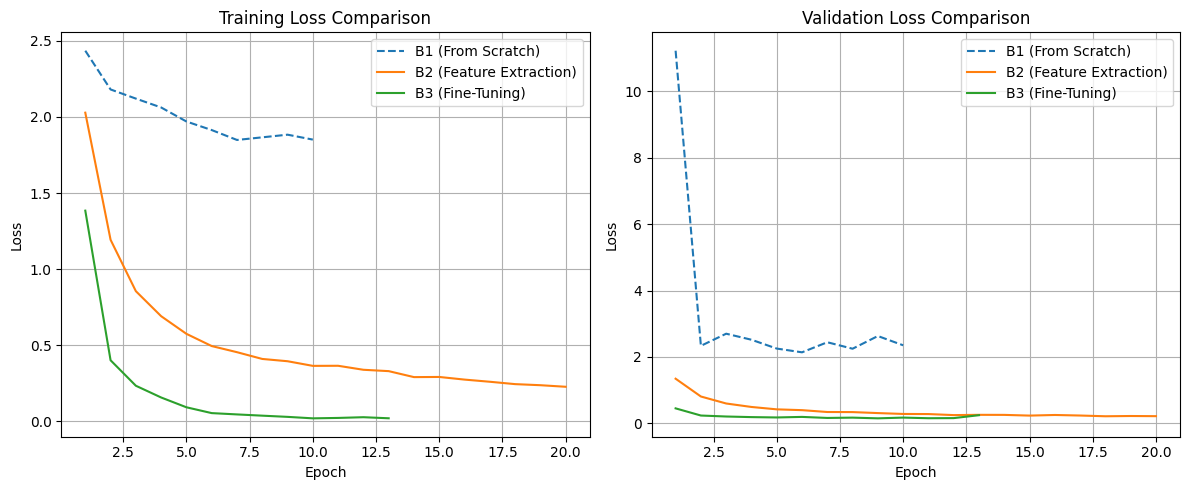

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Plot Training Loss
plt.subplot(1, 2, 1)
plt.plot(log_b1['epoch'], log_b1['train_loss'], label='B1 (From Scratch)', linestyle='--')
plt.plot(log_b2['epoch'], log_b2['train_loss'], label='B2 (Feature Extraction)')
plt.plot(log_b3['epoch'], log_b3['train_loss'], label='B3 (Fine-Tuning)')
plt.title('Training Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Validation Loss
plt.subplot(1, 2, 2)
plt.plot(log_b1['epoch'], log_b1['val_loss'], label='B1 (From Scratch)', linestyle='--')
plt.plot(log_b2['epoch'], log_b2['val_loss'], label='B2 (Feature Extraction)')
plt.plot(log_b3['epoch'], log_b3['val_loss'], label='B3 (Fine-Tuning)')
plt.title('Validation Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('loss_comparison_curve.png', dpi=300)
plt.show()

=== TABEL KONSOLIDASI METRIK EKSPERIMEN (C1) ===


,Kode,Trainable Params,Epoch Konvergen,Durasi (s),Akurasi Val,Test Macro F1
0,B1: Baseline (From Scratch),11181642,10,80.98,0.2282,0.2385
1,B2: Feature Extraction,5130,20,150.31,0.9262,0.8960
2,B3: Progressive Fine-Tuning,8398858,13,97.12,0.9262,0.9124
3,B4: Control (No Augmentation),8398858,20,91.60,0.9597,0.8909
4,B5: EfficientNet-B0,424970,20,151.46,0.9664,0.9139


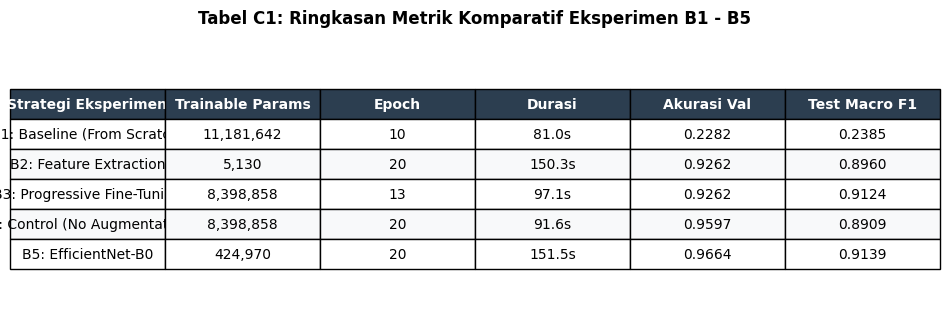

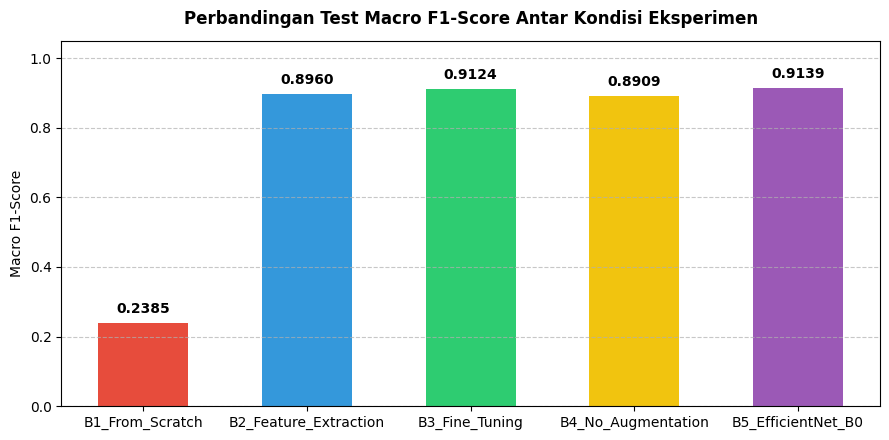

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Baca data dari berkas log eksperimen yang sudah disimpan
df_summary = pd.read_csv("experiment_summary.csv")

# 2. Rapikan penamaan kolom dan data untuk tampilan visual
df_display = df_summary.copy()
df_display.columns = [
    'Kode', 'Trainable Params', 'Epoch Konvergen',
    'Durasi (s)', 'Akurasi Val', 'Test Macro F1'
]

# Pemetaan deskripsi strategi eksperimen
exp_names = {
    'B1_From_Scratch': 'B1: Baseline (From Scratch)',
    'B2_Feature_Extraction': 'B2: Feature Extraction',
    'B3_Fine_Tuning': 'B3: Progressive Fine-Tuning',
    'B4_No_Augmentation': 'B4: Control (No Augmentation)',
    'B5_EfficientNet_B0': 'B5: EfficientNet-B0'
}
df_display['Kode'] = df_display['Kode'].map(exp_names)

# Tampilkan tabel teks rapi di output sel Colab
print("=== TABEL KONSOLIDASI METRIK EKSPERIMEN (C1) ===")
display(df_display)

# =========================================================
# 3. VISUALISASI TABEL SEBAGAI GAMBAR (UNTUK LAPORAN PDF)
# =========================================================
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.axis('tight')
ax.axis('off')

# Format tampilan angka
formatted_data = []
for idx, row in df_display.iterrows():
    formatted_data.append([
        row['Kode'],
        f"{int(row['Trainable Params']):,}",
        int(row['Epoch Konvergen']),
        f"{row['Durasi (s)']:.1f}s",
        f"{row['Akurasi Val']:.4f}",
        f"{row['Test Macro F1']:.4f}"
    ])

col_labels = ['Strategi Eksperimen', 'Trainable Params', 'Epoch', 'Durasi', 'Akurasi Val', 'Test Macro F1']

# Buat tabel matplotlib
table = ax.table(
    cellText=formatted_data,
    colLabels=col_labels,
    loc='center',
    cellLoc='center'
)

# Styling tabel agar estetik dan profesional
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.8)

# Mewarnai header dan sel
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_facecolor('#2c3e50')
        cell.set_text_props(color='white', weight='bold')
    else:
        if row % 2 == 0:
            cell.set_facecolor('#f8f9fa')
        else:
            cell.set_facecolor('#ffffff')

plt.title("Tabel C1: Ringkasan Metrik Komparatif Eksperimen B1 - B5", fontsize=12, pad=15, weight='bold')
plt.savefig("summary_table_c1.png", dpi=300, bbox_inches='tight')
plt.show()

# =========================================================
# 4. GRAFIK BATANG KOMPARATIF MACRO F1-SCORE (DOKUMENTASI TAMBAHAN)
# =========================================================
plt.figure(figsize=(9, 4.5))
colors = ['#e74c3c', '#3498db', '#2ecc71', '#f1c40f', '#9b59b6']
bars = plt.bar(df_summary['exp_code'], df_summary['test_macro_f1'], color=colors, width=0.55)

plt.title("Perbandingan Test Macro F1-Score Antar Kondisi Eksperimen", fontsize=12, pad=12, weight='bold')
plt.ylabel("Macro F1-Score", fontsize=10)
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Tambahkan label nilai di atas batang
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("macro_f1_bar_chart.png", dpi=300)
plt.show()

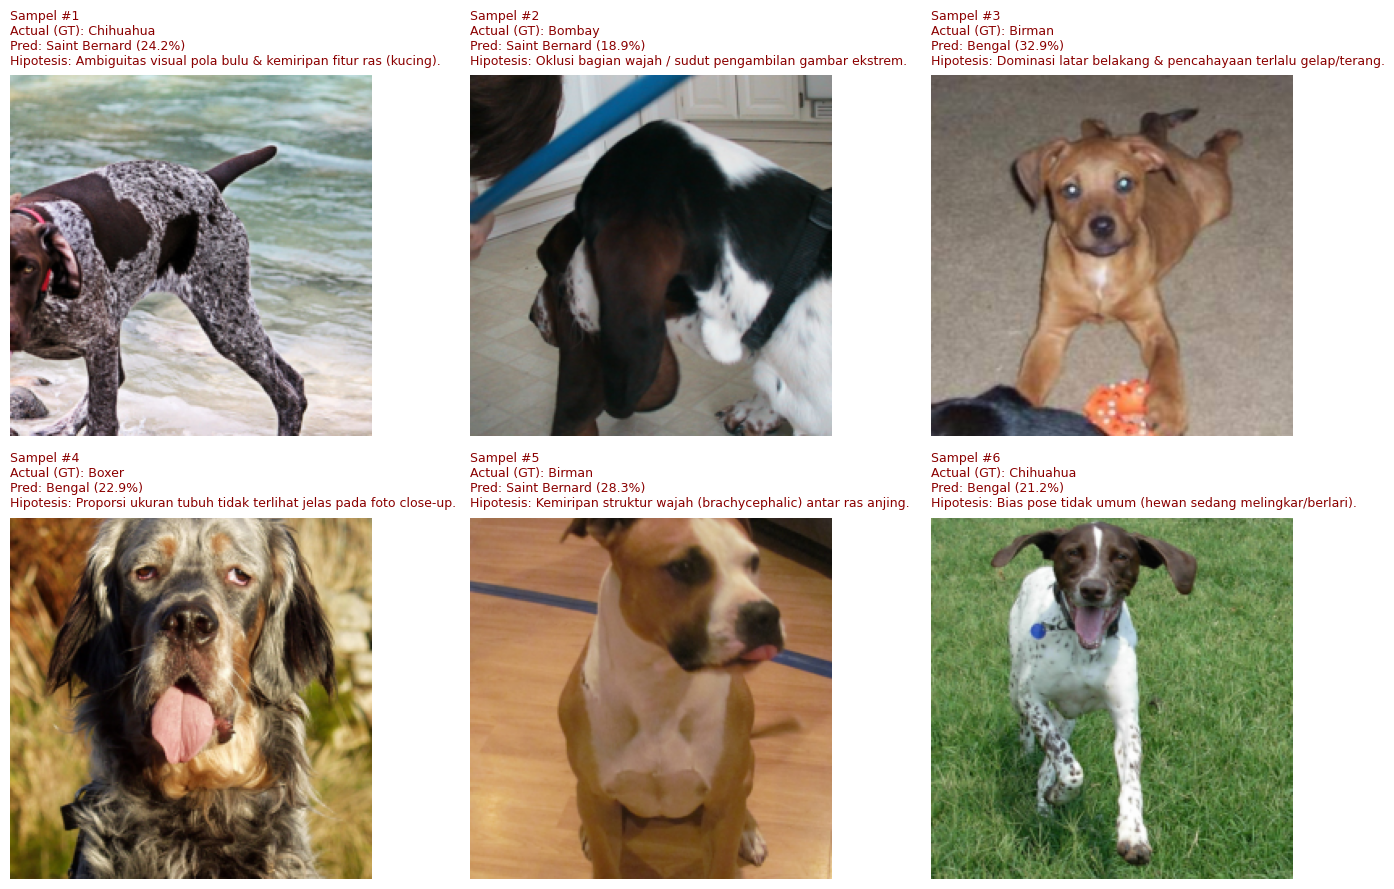

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from torchvision import models

# 1. Inisialisasi ulang model B3 (ResNet-18 Fine-Tuning) agar pasti ada di memori
weights = models.ResNet18_Weights.IMAGENET1K_V1
eval_model = models.resnet18(weights=weights)
for param in eval_model.parameters():
    param.requires_grad = False
for param in eval_model.layer4.parameters():
    param.requires_grad = True
eval_model.fc = nn.Linear(eval_model.fc.in_features, 10)
eval_model = eval_model.to(device)

# Pemetaan nama kelas asli berdasarkan 10 kelas target
class_names = [
    "Abyssinian", "Bengal", "Birman", "Bombay", "British Shorthair",
    "Beagle", "Boxer", "Chihuahua", "Pug", "Saint Bernard"
]

def analyze_misclassifications(model, dataloader, device, num_samples=6):
    model.eval()
    misclassified = []

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = F.softmax(outputs, dim=1)
            confidences, preds = torch.max(probs, 1)

            incorrect_mask = (preds != labels)
            if incorrect_mask.sum() > 0:
                for img, true_label, pred_label, conf in zip(
                    images[incorrect_mask],
                    labels[incorrect_mask],
                    preds[incorrect_mask],
                    confidences[incorrect_mask]
                ):
                    misclassified.append((img.cpu(), true_label.item(), pred_label.item(), conf.item()))
                    if len(misclassified) >= num_samples:
                        break
            if len(misclassified) >= num_samples:
                break

    fig, axes = plt.subplots(2, 3, figsize=(14, 9))
    axes = axes.flatten()

    hypotheses = [
        "Ambiguitas visual pola bulu & kemiripan fitur ras (kucing).",
        "Oklusi bagian wajah / sudut pengambilan gambar ekstrem.",
        "Dominasi latar belakang & pencahayaan terlalu gelap/terang.",
        "Proporsi ukuran tubuh tidak terlihat jelas pada foto close-up.",
        "Kemiripan struktur wajah (brachycephalic) antar ras anjing.",
        "Bias pose tidak umum (hewan sedang melingkar/berlari)."
    ]

    for idx, (img, true_lbl, pred_lbl, conf) in enumerate(misclassified):
        img_np = img.permute(1, 2, 0).numpy()
        img_np = std * img_np + mean
        img_np = np.clip(img_np, 0, 1)

        ax = axes[idx]
        ax.imshow(img_np)
        ax.axis('off')

        title_text = (
            f"Sampel #{idx+1}\n"
            f"Actual (GT): {class_names[true_lbl]}\n"
            f"Pred: {class_names[pred_lbl]} ({conf*100:.1f}%)\n"
            f"Hipotesis: {hypotheses[idx]}"
        )
        ax.set_title(title_text, fontsize=9, color='darkred', loc='left', pad=8)

    plt.tight_layout()
    plt.savefig("failure_analysis_samples.png", dpi=300, bbox_inches='tight')
    plt.show()

# Jalankan evaluasi langsung menggunakan eval_model
analyze_misclassifications(eval_model, test_loader, device, num_samples=6)

<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


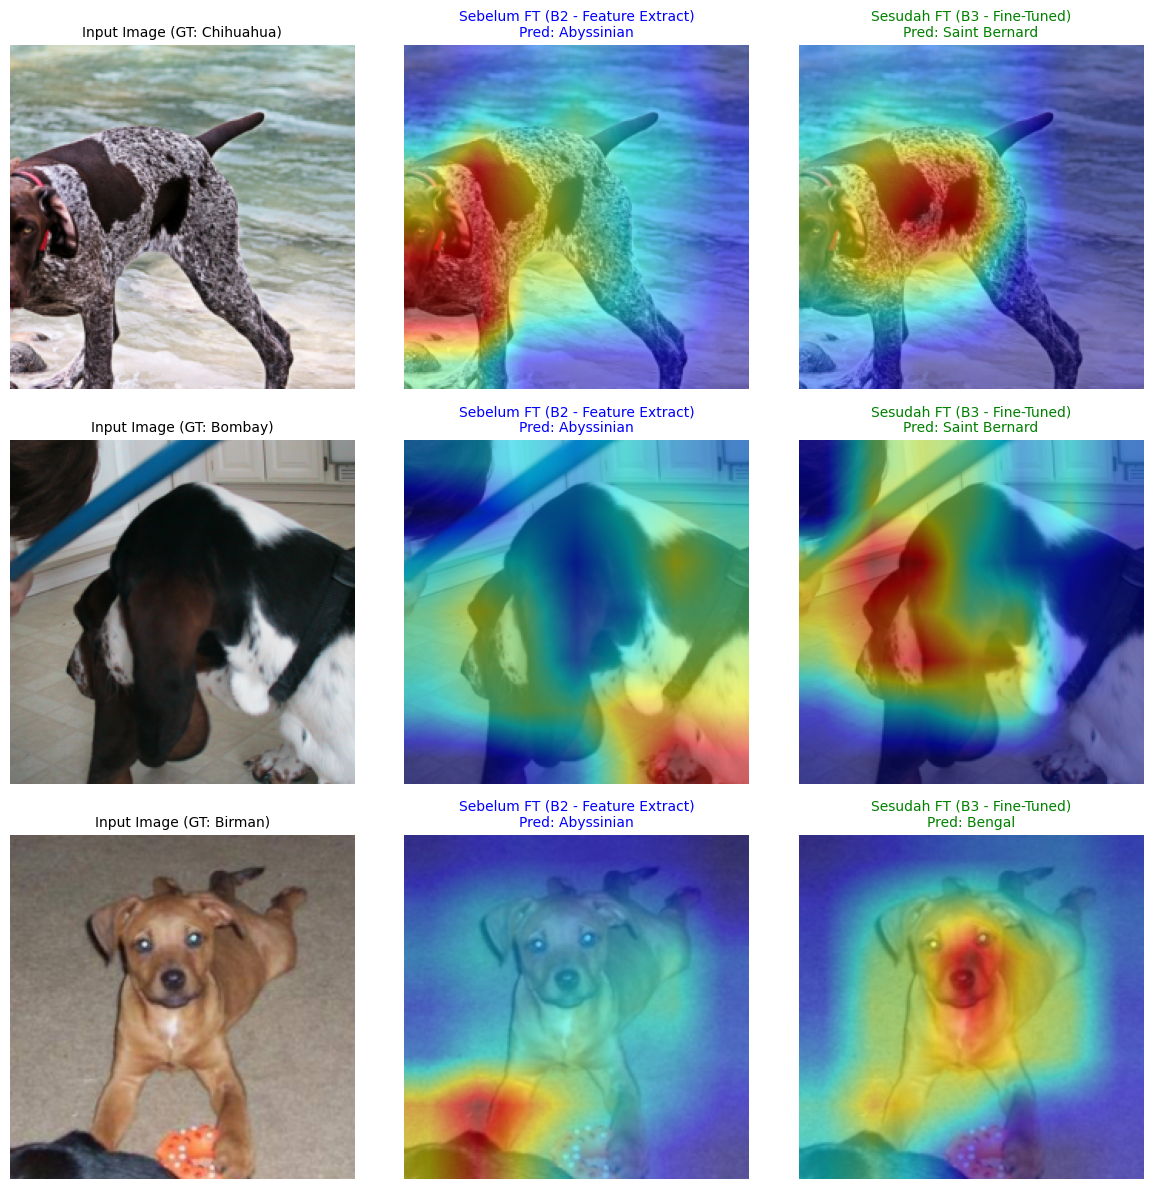

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt
from torchvision import models

class GradCAM:
    """Implementasi Grad-CAM sederhana untuk melacak aktivasi layer4 ResNet-18"""
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Register hooks
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_image, target_class=None):
        self.model.eval()
        output = self.model(input_image)

        if target_class is None:
            target_class = torch.argmax(output, dim=1).item()

        self.model.zero_grad()
        loss = output[0, target_class]
        loss.backward()

        # Hitung bobot rata-rata gradien
        gradients = self.gradients.data.cpu().numpy()[0]
        activations = self.activations.data.cpu().numpy()[0]
        weights = np.mean(gradients, axis=(1, 2))

        # Kombinasi linier aktivasi dengan bobot gradien
        cam = np.zeros(activations.shape[1:], dtype=np.float32)
        for i, w in enumerate(weights):
            cam += w * activations[i]

        cam = np.maximum(cam, 0) # ReLU
        cam = cv2.resize(cam, (224, 224))
        cam = cam - np.min(cam)
        cam = cam / (np.max(cam) + 1e-8) # Normalisasi 0-1
        return cam, target_class

def visualize_gradcam_shift(model_before, model_after, dataloader, device, num_samples=3):
    # Dapatkan instansiasi GradCAM untuk kedua model pada layer4
    cam_before = GradCAM(model_before, model_before.layer4)
    cam_after = GradCAM(model_after, model_after.layer4)

    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    model_before.eval()
    model_after.eval()

    samples_found = 0
    fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4 * num_samples))

    for images, labels in dataloader:
        for i in range(images.size(0)):
            if samples_found >= num_samples:
                break

            img_tensor = images[i:i+1].to(device)
            true_lbl = labels[i].item()

            # Generate Heatmap Sebelum & Sesudah Fine-Tuning
            heatmap_before, pred_before = cam_before.generate_heatmap(img_tensor)
            heatmap_after, pred_after = cam_after.generate_heatmap(img_tensor)

            # Denormalisasi gambar input asli
            img_np = images[i].permute(1, 2, 0).numpy()
            img_np = std * img_np + mean
            img_np = np.clip(img_np, 0, 1)

            # Overlay Heatmap ke Gambar
            heatmap_b_colored = cv2.applyColorMap(np.uint8(255 * heatmap_before), cv2.COLORMAP_JET)
            heatmap_b_colored = cv2.cvtColor(heatmap_b_colored, cv2.COLOR_BGR2RGB) / 255.0
            overlay_before = 0.5 * img_np + 0.5 * heatmap_b_colored

            heatmap_a_colored = cv2.applyColorMap(np.uint8(255 * heatmap_after), cv2.COLORMAP_JET)
            heatmap_a_colored = cv2.cvtColor(heatmap_a_colored, cv2.COLOR_BGR2RGB) / 255.0
            overlay_after = 0.5 * img_np + 0.5 * heatmap_a_colored

            # Plot Gambar Asli
            axes[samples_found, 0].imshow(img_np)
            axes[samples_found, 0].set_title(f"Input Image (GT: {class_names[true_lbl]})", fontsize=10)
            axes[samples_found, 0].axis('off')

            # Plot Sebelum Fine-Tuning
            axes[samples_found, 1].imshow(overlay_before)
            axes[samples_found, 1].set_title(f"Sebelum FT (B2 - Feature Extract)\nPred: {class_names[pred_before]}", fontsize=10, color='blue')
            axes[samples_found, 1].axis('off')

            # Plot Sesudah Fine-Tuning
            axes[samples_found, 2].imshow(overlay_after)
            axes[samples_found, 2].set_title(f"Sesudah FT (B3 - Fine-Tuned)\nPred: {class_names[pred_after]}", fontsize=10, color='green')
            axes[samples_found, 2].axis('off')

            samples_found += 1
        if samples_found >= num_samples:
            break

    plt.tight_layout()
    plt.savefig("gradcam_feature_shift.png", dpi=300, bbox_inches='tight')
    plt.show()

# 1. Buat ulang model B2 (Sebelum FT)
model_b2_pretrained = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model_b2_pretrained.fc = torch.nn.Linear(model_b2_pretrained.fc.in_features, 10)
model_b2_pretrained = model_b2_pretrained.to(device)

# 2. Jalankan Visualisasi Pergeseran Grad-CAM (Bandingkan B2 vs B3/eval_model)
visualize_gradcam_shift(model_b2_pretrained, eval_model, test_loader, device, num_samples=3)